# Mean Surface Temperature

Projected annual mean near-surface air temperature (`tas`) at the selected site from the CSIRO CMIP6 multi-model ensemble, and the local temperature reached at each global warming level.

```{glue:figure} gwl_box_fig
:scale: 60%
:align: right
```

**Figure. Local annual mean temperature at global warming levels.** Each box shows the spread across models in the year each scenario first reaches the level (years below each group).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_projection_palau, get_box_data, plot_global_warming_boxplot

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Scenarios and global warming levels

Years at which the IPCC AR6 multi-model mean global surface temperature first reaches each warming level (°C above 1850–1900), computed in [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). Local values are read from every model at those years.

In [5]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
incr_temps = list(prj.WARMING_LEVELS)
delta_t = 0  # warming levels are already expressed relative to 1850–1900

scenario_info = prj.load_warming_levels(ssp_scenarios)
pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

,ssp126,ssp245,ssp370,ssp585
+1.5°C,2032-01-01,2030-01-01,2030-01-01,2027-01-01
+2.0°C,NaT,2052-01-01,2046-01-01,2041-01-01
+2.5°C,NaT,2079-01-01,2061-01-01,2053-01-01
+3.0°C,NaT,NaT,2075-01-01,2064-01-01


### Get data

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid (one file per scenario and variable, `ensemble_<ssp>_<variable>_commongrid.nc`). The series at the grid cell nearest to the site is cached under `data/projections/<site_tag>/`; delete that file or set `overwrite=True` to extract it again.

In [6]:
ds = prj.extract_point("tas", site_lon, site_lat, ssp_scenarios, cache_file=cache_dir / "tas_point.nc")
print(f"Grid cell used: lon {ds.attrs['grid_lon']}, lat {ds.attrs['grid_lat']}; models per scenario:",
      {sc: int(ds.tas.sel(scenario=sc).isel(time=0).notnull().sum()) for sc in ssp_scenarios})

Grid cell used: lon 134.0, lat 7.0; models per scenario: {'ssp126': 38, 'ssp245': 38, 'ssp370': 38, 'ssp585': 38}


Temperature change `tas_ref` is expressed relative to each model's 2015–2035 mean plus `delta_t0` = 1.2 °C, the observed global warming of that period relative to 1850–1900, so that it is comparable with the warming levels.

In [7]:
delta_t0 = 1.2
ds["tas_ref"] = ds["tas"] - ds["tas"].sel(time=slice("2015", "2035")).mean("time") + delta_t0

## Analysis

### Projected annual mean temperature

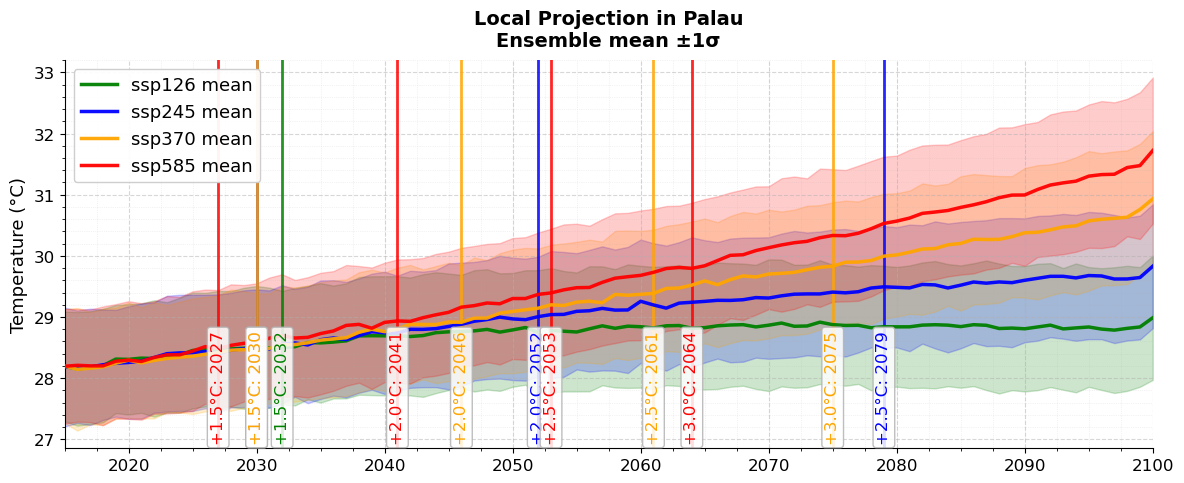

In [8]:
fig, ax = plot_projection_palau(ds, "tas", scenario_info, ssp_scenarios, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "air_temp_mean_timeseries", site_tag)
glue("timeseries_fig", fig, display=False)

### Temperature at global warming levels

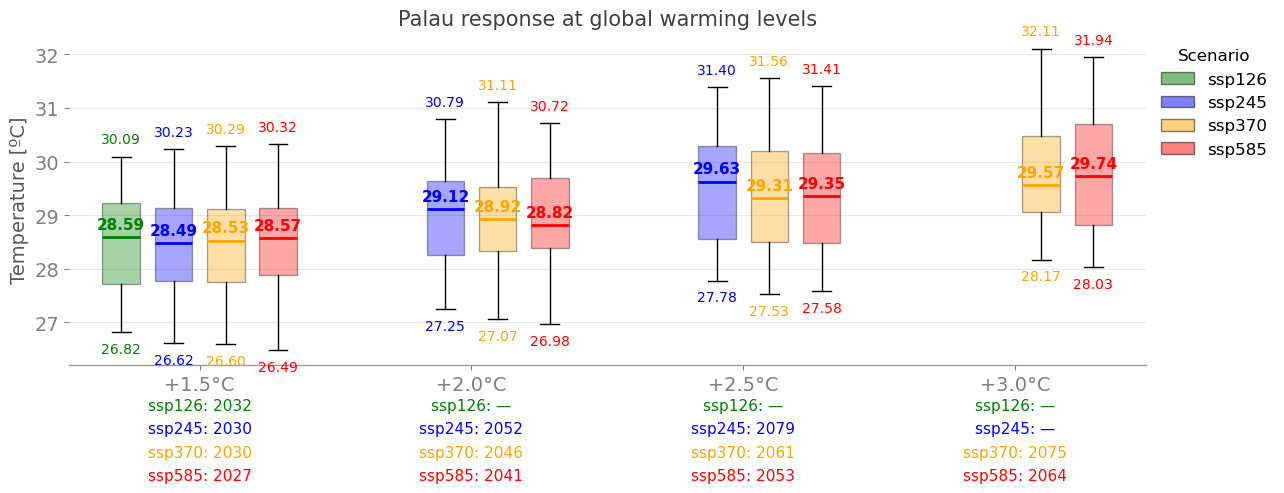

In [9]:
box_data, box_scenarios, positions = get_box_data(ds, scenario_info, incr_temps, ssp_scenarios, "tas")
fig, ax = plot_global_warming_boxplot(box_data, ds, positions, box_scenarios, scenario_info, incr_temps, "tas",
                                      plot_ref=False, texts=True, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "air_temp_mean_gwl", site_tag)
glue("gwl_box_fig", fig, display=False)

In [10]:
table = prj.gwl_summary(ds, "tas", scenario_info, ssp_scenarios, decimals=2)
prj.save_table(table, tables_dir, "air_temp_mean_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,SSP126,+1.5°C,2032,38,28.59,27.10,29.68,26.82,30.09
1,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,SSP245,+1.5°C,2030,38,28.49,27.18,29.60,26.62,30.23
5,SSP245,+2.0°C,2052,38,29.12,27.75,30.36,27.25,30.79
6,SSP245,+2.5°C,2079,38,29.63,28.18,30.84,27.78,31.40
7,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,SSP370,+1.5°C,2030,38,28.53,27.26,29.58,26.60,30.29
9,SSP370,+2.0°C,2046,38,28.92,27.74,29.86,27.07,31.11


PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_air_temp_change_gwl_palau_psw00040309_lat7p337_lon134p477.png')

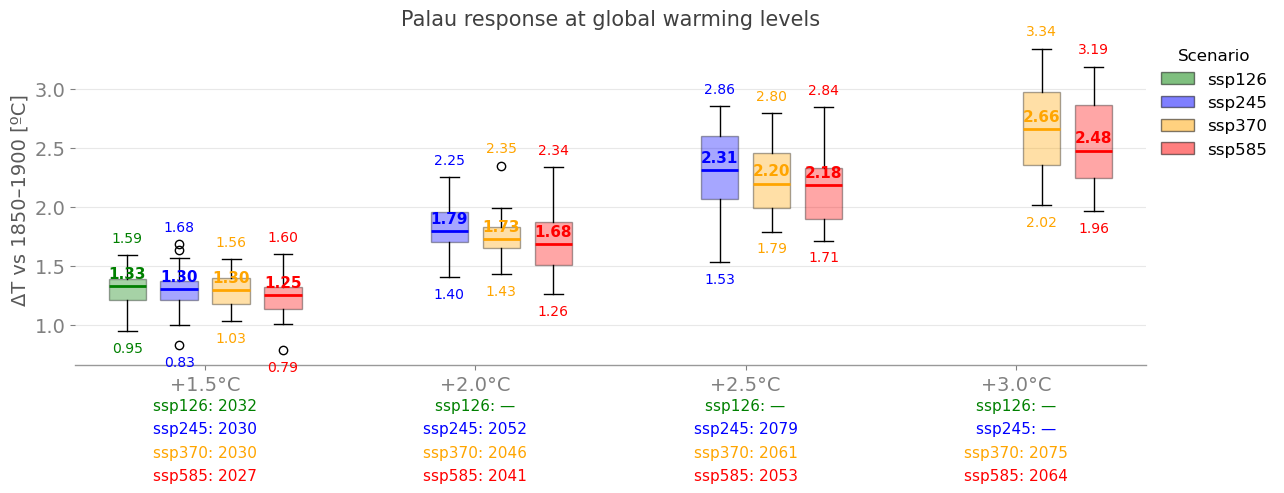

In [11]:
box_data, box_scenarios, positions = get_box_data(ds, scenario_info, incr_temps, ssp_scenarios, "tas_ref")
fig, ax = plot_global_warming_boxplot(box_data, ds, positions, box_scenarios, scenario_info, incr_temps, "tas_ref",
                                      plot_ref=False, texts=True, delta_t=delta_t, site_label=site_label,
                                      ylabel="ΔT vs 1850–1900 [ºC]")
prj.save_figure(fig, fig_dir, "air_temp_change_gwl", site_tag)

In [12]:
table = prj.gwl_summary(ds, "tas_ref", scenario_info, ssp_scenarios, decimals=2)
prj.save_table(table, tables_dir, "air_temp_change_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,SSP126,+1.5°C,2032,38,1.33,1.11,1.50,0.95,1.59
1,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,SSP245,+1.5°C,2030,38,1.30,1.07,1.49,0.83,1.68
5,SSP245,+2.0°C,2052,38,1.79,1.59,2.04,1.40,2.25
6,SSP245,+2.5°C,2079,38,2.31,1.85,2.76,1.53,2.86
7,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,SSP370,+1.5°C,2030,38,1.30,1.13,1.49,1.03,1.56
9,SSP370,+2.0°C,2046,38,1.73,1.56,1.95,1.43,2.35
